<a href="https://colab.research.google.com/github/anshikapuri2115/concrete-strength-prediction/blob/main/concrete_strength_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Concrete Compressive Strength Prediction

Predicting concrete compressive strength (MPa) from mix proportions and curing age using machine learning.

## Dataset
UCI Concrete Compressive Strength dataset: 1,030 samples, 8 input features
(cement, slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate, age).

## Approach
1. Explored the data (shape, types, missing values, ranges).
2. 80/20 train-test split (random_state=42).
3. Baseline: Linear Regression.
4. Feature engineering: water-cement ratio (Abrams' law) and log(age).
5. Random Forest (200 trees) and 5-fold shuffled cross-validation.
6. Error analysis by age band and feature importance.

## Results (held-out test set)
| Model | R2 | RMSE (MPa) |
|---|---|---|
| Linear Regression, raw features | 0.628 | 9.80 |
| Linear Regression, + engineered features | 0.833 | 6.56 |
| Random Forest, raw features | 0.881 | 5.53 |
| Random Forest, + engineered features | 0.888 | 5.38 |

5-fold shuffled CV (Random Forest): mean R2 = 0.906 +/- 0.014.

## Key findings
- Engineered features raised Linear Regression R2 from 0.63 to 0.83; Random Forest gained little (0.881 to 0.888), likely because trees learn non-linearity themselves.
- Water-cement ratio was the most important feature, consistent with Abrams' law.
- Error was highest for 7-28 day mixes (MAE about 4.2 MPa) and lowest for 90+ days (about 2.9 MPa).
- The dataset is ordered: CV without shuffling gave an unstable fold (negative R2), fixed with shuffled K-fold.

## Limitations
- The dataset may contain the same mix tested at several ages, so a random split can be optimistic. A group-based split was not tested.
- Lab data may not transfer to site conditions.

## How to run
Open the notebook in Google Colab and run all cells.

In [17]:
import pandas as pd
import numpy as np
print("pandas:", pd.__version__)
print("numpy:", np.__version__)


pandas: 2.2.3
numpy: 2.4.6


In [18]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=165)
X = data.data.features
y = data.data.targets
df = pd.concat([X, y], axis=1)
print(df.shape)

(1030, 9)


In [19]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [21]:
df.isnull().sum()

,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,0


In [22]:
df.columns.tolist()

['Cement',
 'Blast Furnace Slag',
 'Fly Ash',
 'Water',
 'Superplasticizer',
 'Coarse Aggregate',
 'Fine Aggregate',
 'Age',
 'Concrete compressive strength']

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Concrete compressive strength"])
y = df["Concrete compressive strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(824, 8) (206, 8)


In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Train R2:", round(lr.score(X_train, y_train), 3))
print("Test R2:", round(r2_score(y_test, y_pred_lr), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 2), "MPa")

Train R2: 0.611
Test R2: 0.628
Test RMSE: 9.8 MPa


In [25]:
df["w_c_ratio"] = df["Water"] / df["Cement"]

X = df.drop(columns=["Concrete compressive strength"])
y = df["Concrete compressive strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr2 = LinearRegression()
lr2.fit(X_train, y_train)
y_pred_lr2 = lr2.predict(X_test)

print("Test R2:", round(r2_score(y_test, y_pred_lr2), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lr2)), 2), "MPa")

Test R2: 0.633
Test RMSE: 9.73 MPa


In [26]:
df["log_age"] = np.log(df["Age"])

X = df.drop(columns=["Concrete compressive strength"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr3 = LinearRegression()
lr3.fit(X_train, y_train)
y_pred_lr3 = lr3.predict(X_test)

print("Test R2:", round(r2_score(y_test, y_pred_lr3), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lr3)), 2), "MPa")

Test R2: 0.833
Test RMSE: 6.56 MPa


In [27]:
!pip install ucimlrepo
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

data = fetch_ucirepo(id=165)
df = pd.concat([data.data.features, data.data.targets], axis=1)

df["w_c_ratio"] = df["Water"] / df["Cement"]
df["log_age"] = np.log(df["Age"])

X = df.drop(columns=["Concrete compressive strength"])
y = df["Concrete compressive strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(824, 10) (206, 10)


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Train R2:", round(rf.score(X_train, y_train), 3))
print("Test R2:", round(r2_score(y_test, y_pred_rf), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2), "MPa")

Train R2: 0.986
Test R2: 0.888
Test RMSE: 5.38 MPa


In [29]:
cols = ["Age", "Cement", "Concrete compressive strength"]

print("First 206 rows (average):")
print(df.iloc[:206][cols].mean().round(1))
print()
print("Last 206 rows (average):")
print(df.iloc[-206:][cols].mean().round(1))

First 206 rows (average):
Age                               76.3
Cement                           345.3
Concrete compressive strength     48.0
dtype: float64

Last 206 rows (average):
Age                               27.8
Cement                           226.3
Concrete compressive strength     32.9
dtype: float64


In [30]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf, X, y, cv=kf, scoring="r2")

print("Fold scores:", scores.round(3))
print("Mean R2:", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

Fold scores: [0.884 0.913 0.899 0.908 0.927]
Mean R2: 0.906 +/- 0.014


In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

raw_cols = [c for c in X.columns if c not in ["w_c_ratio", "log_age"]]
all_cols = list(X.columns)

experiments = [
    ("Linear Regression, raw features", LinearRegression(), raw_cols),
    ("Linear Regression, + engineered", LinearRegression(), all_cols),
    ("Random Forest, raw features", RandomForestRegressor(n_estimators=200, random_state=42), raw_cols),
    ("Random Forest, + engineered", RandomForestRegressor(n_estimators=200, random_state=42), all_cols),
]

for name, model, cols in experiments:
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name}: R2 = {r2:.3f}, RMSE = {rmse:.2f} MPa")

Linear Regression, raw features: R2 = 0.628, RMSE = 9.80 MPa
Linear Regression, + engineered: R2 = 0.833, RMSE = 6.56 MPa
Random Forest, raw features: R2 = 0.881, RMSE = 5.53 MPa
Random Forest, + engineered: R2 = 0.888, RMSE = 5.38 MPa


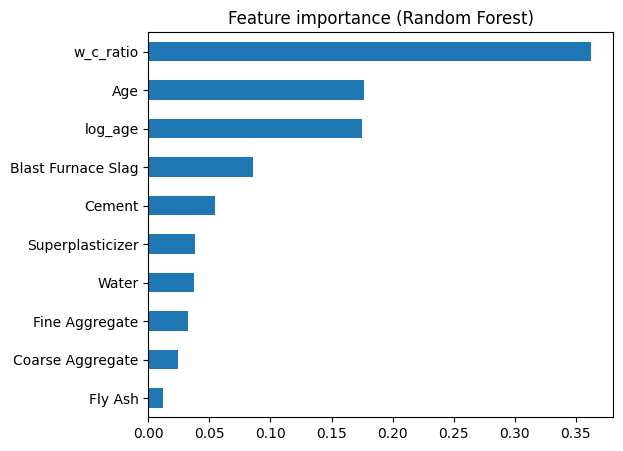

In [32]:
import matplotlib.pyplot as plt

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
imp.plot(kind="barh", figsize=(6, 5))
plt.title("Feature importance (Random Forest)")
plt.show()

In [33]:
import pandas as pd

residuals = y_test - y_pred_rf
err = pd.DataFrame({"Age": X_test["Age"], "abs_error": residuals.abs()})
bins = pd.cut(err["Age"], [0, 7, 28, 90, 400])
print(err.groupby(bins, observed=True)["abs_error"].agg(["count", "mean"]).round(2))

           count  mean
Age                   
(0, 7]        56  3.51
(7, 28]       91  4.16
(28, 90]      29  3.47
(90, 400]     30  2.87


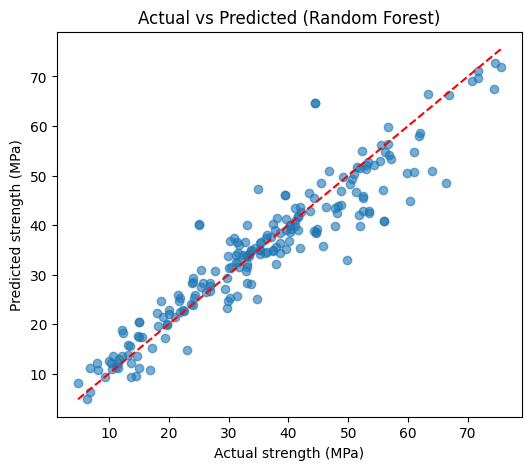

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()